### Network Visualization 
#### SYSE-580B3
#### Mason Lu

Loading road-density measurements...
Grid cells: 4,122
Maximum density: 19.1068 km/km²
Loading California road network...
Road features: 723,692
Assigning density values to road features...
Roads assigned density values: 723,692
Preparing road geometries for plotting...
Drawable road lines: 835,096
Generating California road-density map...


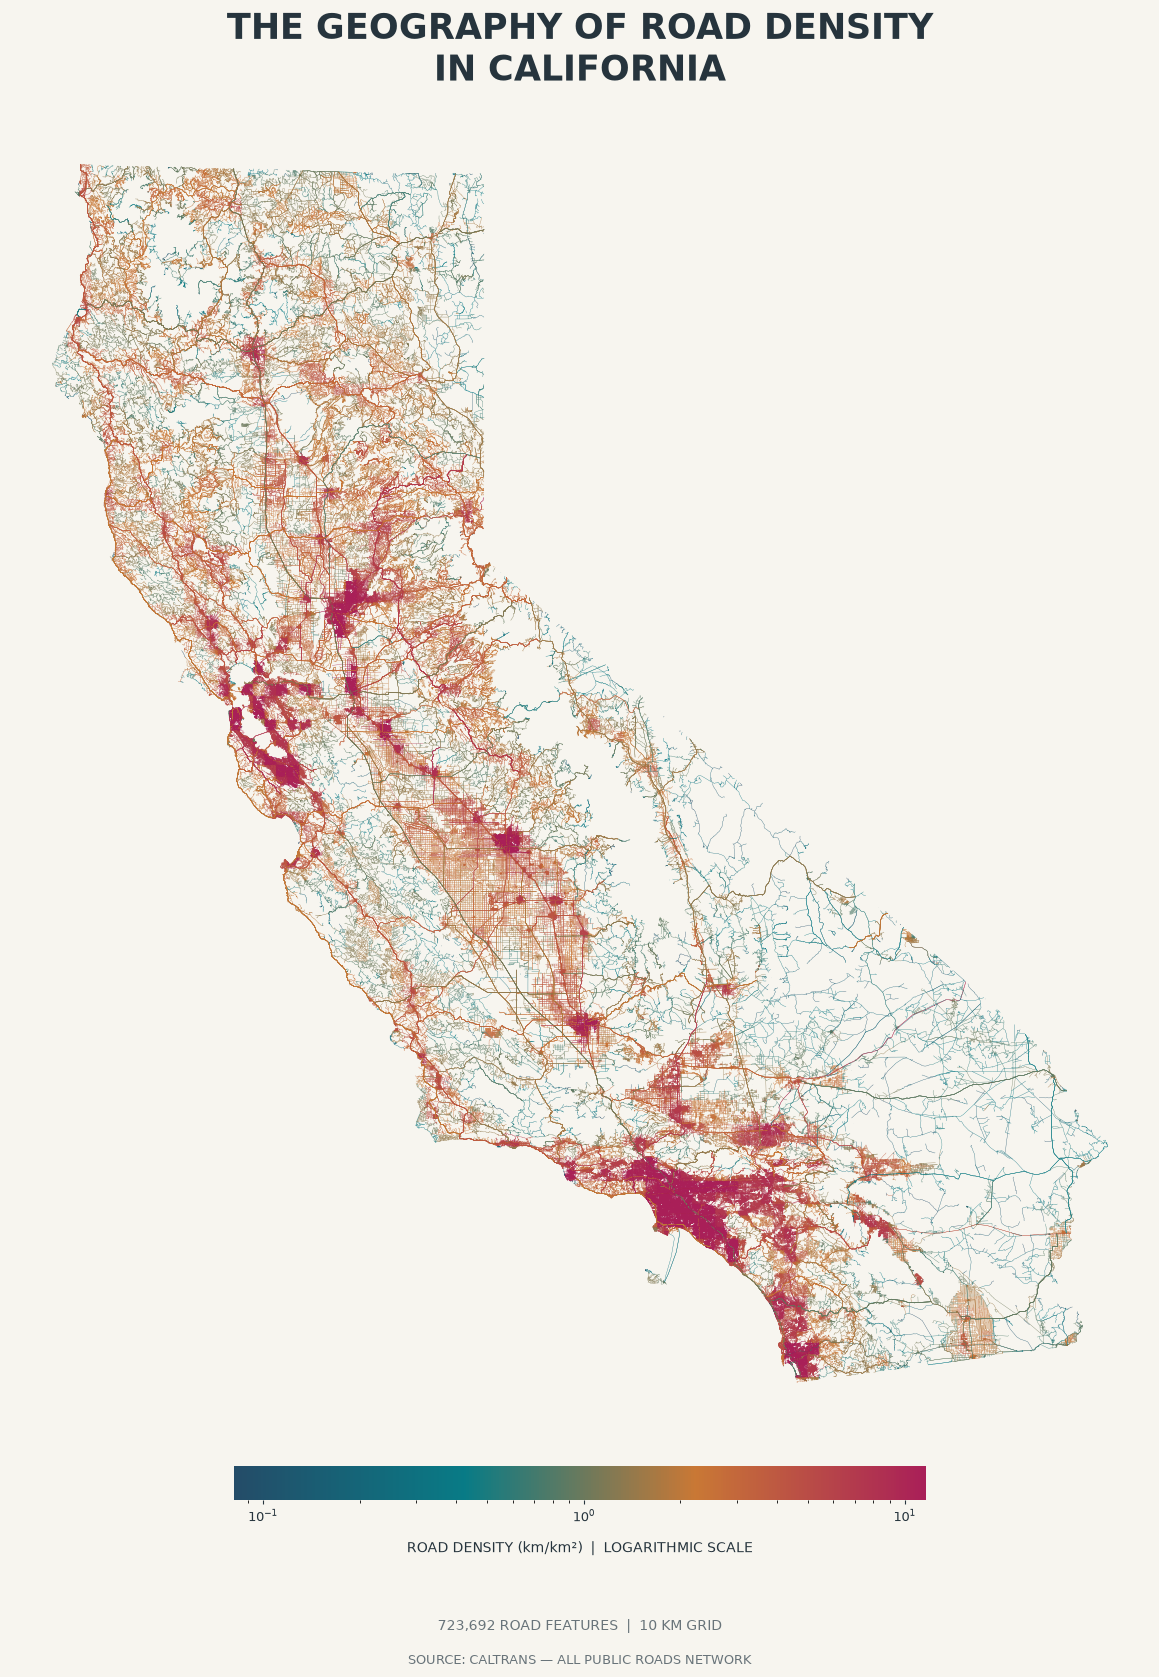


Visualization saved to:
/Users/masonlu/Desktop/CSU (SYSE)/SYSE 580B3/NetworkVisualization/LuMason_NetworkViz.png


In [11]:

"""
The Geography of Road Density in California

This script visualizes the spatial distribution of California's public
road infrastructure using road-density measurements calculated over
a 10 km x 10 km geographic grid.

Data source:
California Department of Transportation (Caltrans)
All Public Roads Network
"""

# ==================================================
# 1. Import Libraries
# ==================================================

import os
import gc
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.cm import ScalarMappable
from shapely.geometry import LineString, MultiLineString


# ==================================================
# 2. Project Configuration
# ==================================================

project_folder = "/Users/masonlu/Desktop/CSU (SYSE)/SYSE 580B3/NetworkVisualization"

shp_path = os.path.join(
    project_folder,
    "California_All_Public_Roads_Network.shp"
)

density_file = os.path.join(
    project_folder,
    "California_Road_Density_10km.csv"
)

output_file = os.path.join(
    project_folder,
    "LuMason_NetworkViz.png"
)

cell_size = 10000  # Grid-cell width in meters

background_color = "#F7F5EF"
title_color = "#26343D"
secondary_color = "#69747A"

road_colors = [
    "#244C68",  # Deep blue
    "#087B86",  # Teal
    "#C97835",  # Orange
    "#A91F58"   # Magenta
]


# ==================================================
# 3. Load Road-Density Data
# ==================================================

print("Loading road-density measurements...")

if not os.path.isfile(density_file):
    raise FileNotFoundError(
        f"Road-density CSV not found: {density_file}"
    )

density = pd.read_csv(density_file)

density_lookup = {
    (int(row.grid_x), int(row.grid_y)): float(row.density)
    for row in density.itertuples()
}

print(f"Grid cells: {len(density):,}")
print(f"Maximum density: {density['density'].max():.4f} km/km²")


# ==================================================
# 4. Define Road-Density Color Scale
# ==================================================

cmap = LinearSegmentedColormap.from_list(
    "california_road_density",
    road_colors,
    N=256
)

# Quantile limits improve visual contrast.
# Logarithmic normalization represents the
# wide range of road-density values.

vmin = max(
    density["density"].quantile(0.05),
    0.001
)

vmax = density["density"].quantile(0.99)

norm = LogNorm(
    vmin=vmin,
    vmax=vmax,
    clip=True
)


# ==================================================
# 5. Load California Road Network
# ==================================================

print("Loading California road network...")

if not os.path.isfile(shp_path):
    raise FileNotFoundError(
        f"Shapefile not found: {shp_path}"
    )

roads = gpd.read_file(
    shp_path,
    engine="pyogrio",
    columns=[]
)

# Project road geometries into California
# Albers Equal Area (EPSG:3310).

if roads.crs.to_epsg() != 3310:
    roads = roads.to_crs(epsg=3310)

print(f"Road features: {len(roads):,}")

xmin, ymin, xmax, ymax = roads.total_bounds


# ==================================================
# 6. Assign Local Density to Road Features
# ==================================================

print("Assigning density values to road features...")

# Each road feature is assigned the density of the
# 10 km grid cell containing its length-based midpoint.

midpoints = roads.geometry.interpolate(
    0.5,
    normalized=True
)

grid_x = np.floor(
    midpoints.x.to_numpy() / cell_size
).astype(int)

grid_y = np.floor(
    midpoints.y.to_numpy() / cell_size
).astype(int)

road_density = np.array([
    density_lookup.get((gx, gy), np.nan)
    for gx, gy in zip(grid_x, grid_y)
])

print(
    f"Roads assigned density values: "
    f"{np.isfinite(road_density).sum():,}"
)


# ==================================================
# 7. Prepare Road Geometries
# ==================================================

print("Preparing road geometries for plotting...")

segments = []
segment_density = []

for geom, value in zip(roads.geometry, road_density):

    if geom is None or geom.is_empty:
        continue

    if not np.isfinite(value) or value <= 0:
        continue

    if isinstance(geom, LineString):
        segments.append(
            np.asarray(geom.coords)[:, :2]
        )
        segment_density.append(value)

    elif isinstance(geom, MultiLineString):
        for line in geom.geoms:
            segments.append(
                np.asarray(line.coords)[:, :2]
            )
            segment_density.append(value)

segment_density = np.asarray(segment_density)

print(f"Drawable road lines: {len(segments):,}")

# Free memory before rendering the figure.
del roads
del midpoints
del road_density
gc.collect()


# ==================================================
# 8. Create Visualization
# ==================================================

print("Generating California road-density map...")

fig, ax = plt.subplots(figsize=(13, 17))

fig.patch.set_facecolor(background_color)
ax.set_facecolor(background_color)

line_colors = cmap(norm(segment_density))

road_collection = LineCollection(
    segments,
    colors=line_colors,
    linewidths=0.25,
    alpha=0.92,
    rasterized=True
)

ax.add_collection(road_collection)

# Geographic extent with a small margin.

xpad = (xmax - xmin) * 0.04
ypad = (ymax - ymin) * 0.04

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

ax.set_aspect("equal")
ax.axis("off")


# ==================================================
# 9. Title and Legend
# ==================================================

ax.set_title(
    "THE GEOGRAPHY OF ROAD DENSITY\nIN CALIFORNIA",
    fontsize=25,
    fontweight="bold",
    color=title_color,
    pad=25
)

scalar_map = ScalarMappable(
    norm=norm,
    cmap=cmap
)

scalar_map.set_array([])

colorbar = fig.colorbar(
    scalar_map,
    ax=ax,
    orientation="horizontal",
    fraction=0.025,
    pad=0.025,
    shrink=0.65
)

colorbar.set_label(
    "ROAD DENSITY (km/km²)  |  LOGARITHMIC SCALE",
    fontsize=10,
    color=title_color,
    labelpad=12
)

colorbar.ax.tick_params(
    colors=title_color,
    labelsize=9,
    length=3
)

colorbar.outline.set_visible(False)


# ==================================================
# 10. Figure Annotations
# ==================================================

fig.text(
    0.5,
    0.045,
    "723,692 ROAD FEATURES  |  10 KM GRID",
    ha="center",
    fontsize=10,
    color=secondary_color
)

fig.text(
    0.5,
    0.025,
    "SOURCE: CALTRANS — ALL PUBLIC ROADS NETWORK",
    ha="center",
    fontsize=9,
    color=secondary_color
)

plt.tight_layout(
    rect=[0, 0.08, 1, 0.96]
)


# ==================================================
# 11. Save Visualization
# ==================================================

fig.savefig(
    output_file,
    dpi=200,
    bbox_inches="tight",
    facecolor=background_color
)

plt.show()

print(f"\nVisualization saved to:\n{output_file}")

plt.close(fig)
